# PRUEBA DE ANÁLISIS DE PARADAS

## ANÁLISIS INICIAL
De primeras el análisis se hará sobre una parada concreta, la 5139 correspondiente a la linea 401 siendo la quinta parada de la línea. He escogido esta debido a que la considero muy básica para empezar, puesto que esa parada no tiene correspondencia con ninguna otra línea, por lo tanto los datos de ocupación o de subidas/bajadas no se verían afectados en tanto qué otros autobuses puedan pasar por esa parada, lo cual como caso base es mejor.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


np.random.seed(495794)


#ABRIR EL CSV COMO PANDAS DATAFRAME
data_input = pd.read_csv("../data/clean_data_5939.csv", encoding="utf-8", header=0)
dataset = pd.DataFrame(data_input)

Borramos las columnas que se duplican, como EventTime, TimeSlot e IdExternal, ya que aparecen en ambas tablas mbot y tbso

In [33]:
dataset.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"])

,TripId,IdExternal,EventDate,EventTime,TimeSlot,Line,Direction,LogicVehicle,Weekday,DayType,Season,FreeDay,Stop,TemperatureMax,TemperatureMin,RainProbMin,RainProbMax,Board,DropOff,Occupation
0,01082025401358812637,688c3408e889950da18fe23a,2025-08-01,05:26:04.4940000,5,401,2,3588,V,LA,V,0,5939,23,22,0,1,0,1,17
1,140820254013590122243,689d5785c8fbb8531ebc9776,2025-08-14,05:25:58.0840000,5,401,2,3590,J,LA,V,0,5939,25,23,0,0,1,1,15
2,120720254013577122261,6871d61ce889950da1c78559,2025-07-12,05:25:58.4500000,5,401,2,3577,S,SA,B,0,5939,19,18,0,0,0,0,10
3,010720254013585129331,686355a7e889950da1496551,2025-07-01,05:26:32.7840000,5,401,2,3585,M,LA,M,0,5939,26,24,0,0,2,0,21
4,170920254013507129331,68ca2aa486761436bcd47ae7,2025-09-17,05:26:40.5480000,5,401,2,3507,X,LA,I,0,5939,21,20,0,0,3,0,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9375,04092025401356521219562,68ba047786761436bc593a52,2025-09-04,23:25:43.4250000,23,401,2,3565,J,LA,B,0,5939,20,20,0,0,3,0,43
9376,26102025401358223219290,68fea06686761436bc956b0b,2025-10-26,23:26:04.9020000,23,401,2,3582,D,FE,I,0,5939,9,9,0,0,1,3,32
9377,270820254013581272480,68af790d86761436bc0d1ada,2025-08-27,23:28:50.0250000,23,401,2,3581,X,LA,V,0,5939,23,23,0,0,2,1,22
9378,20072025401875523219519,687d5d10e889950da11e50c6,2025-07-20,23:12:46.3760000,23,401,2,8755,D,FE,B,0,5939,21,21,0,0,3,0,75


Se eliminan aquellas filas cuya ocupación sea < 0, puesto que como se dijo en el documento adjunto con la información de la base de datos, estas instancias no tienen sentido

In [34]:
dataset.shape

(9380, 25)

In [35]:
dataset = dataset[dataset["Occupation"] >=0]
dataset = dataset[dataset["Occupation"] < 500] #Fijamos 500 como valor arbitrariamente grande, puesto que se ha dado el caso que a veces hay valores extremadamente grandes

In [36]:
dataset.shape

(9320, 25)

Se han visto afectadas +- unas 2200 filas, teniendo en quenta que días únicos a día de ejecutar la consulta tenemos unos 120 días, es una media estimada de 18 medidas eliminadas de 210 diarias

## ANÁLISIS POR DÍA
Para comenzar desde lo más básico, vamos a analizar las distribuciones de 1 día cconcreto, porejemplo el lúnes 22/9, y posteriormente, se irán añadiendo más días, para analizar parecidos, o casos partiulares.

In [51]:
data_22_9 = dataset[dataset["EventDate"] == "2025-09-24"]
data_22_9.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"])

,TripId,IdExternal,EventDate,EventTime,TimeSlot,Line,Direction,LogicVehicle,Weekday,DayType,Season,FreeDay,Stop,TemperatureMax,TemperatureMin,RainProbMin,RainProbMax,Board,DropOff,Occupation
51,240920254013585129331,68d3655186761436bc263f10,2025-09-24,05:26:33.4420000,5,401,2,3585,X,LA,I,0,5939,11,10,0,0,4,0,24
146,240920254013578121443,68d3687986761436bc26445e,2025-09-24,05:39:57.8890000,5,401,2,3578,X,LA,I,0,5939,11,10,0,0,0,0,14
217,240920254013579122261,68d36b5986761436bc264c74,2025-09-24,05:52:21.8570000,5,401,2,3579,X,LA,I,0,5939,11,10,0,0,3,1,23
355,240920254013581122243,68d3716e86761436bc266e28,2025-09-24,06:18:40.6770000,6,401,2,3581,X,LA,I,0,5939,18,11,0,0,2,1,23
512,240920254013585329331,68d375b586761436bc26941a,2025-09-24,06:26:02.9250000,6,401,2,3585,X,LA,I,0,5939,18,11,0,0,5,1,31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8682,240920254013587212951,68d44ac486761436bc31db40,2025-09-24,21:39:33.0270000,21,401,2,3587,X,LA,I,0,5939,14,14,0,0,2,1,35
8805,24092025401358218219433,68d44edf86761436bc320857,2025-09-24,22:02:11.0090000,22,401,2,3582,X,LA,I,0,5939,14,14,0,0,0,0,55
9010,24092025401356918217135,68d4547586761436bc324245,2025-09-24,22:17:50.6360000,22,401,2,3569,X,LA,I,0,5939,14,14,0,0,0,1,39
9145,24092025401352621218458,68d45a0286761436bc327731,2025-09-24,22:40:42.0270000,22,401,2,3526,X,LA,I,0,5939,14,14,0,0,1,0,29


A continuación se muestra una distribución del valor de **Occupation** en función del tiempo de registro en la parada. Esto no hace falta reordenarlo,ya que en la propia consulta, se hacía un order by EventTime, lo que nos ayuda a mostrar todos estos estadísticos en función de la hora del día

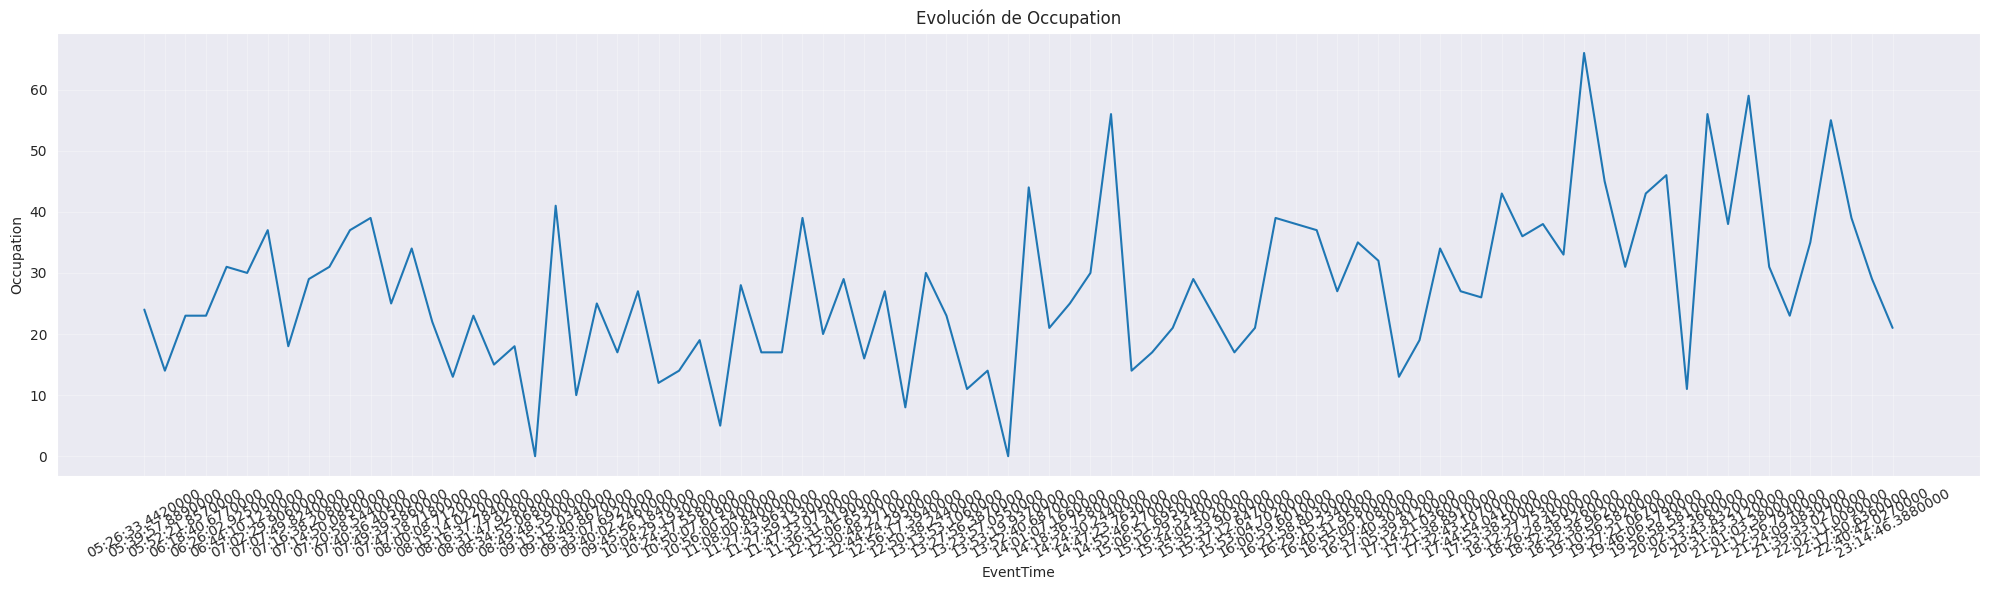

In [52]:
plt.figure(figsize=(20,6))
plt.plot(data_22_9["EventTime"], data_22_9["Occupation"])
plt.xlabel('EventTime')
plt.ylabel('Occupation')
plt.title('Evolución de Occupation')
plt.xticks(rotation=29)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

En la distribución de ocupación a lo largo del tiempo si que se puede observar una cosa curiosa. Se detectan 3 valores de ocupación muy altos, ubicados en las primeras horas de la mañana. lo que quizás nos hacen distorsionar un poco la gráfica. Vamos a poner lla distribución a partr de las 9 de la mañana a ver que aparece o que se pueda observar.

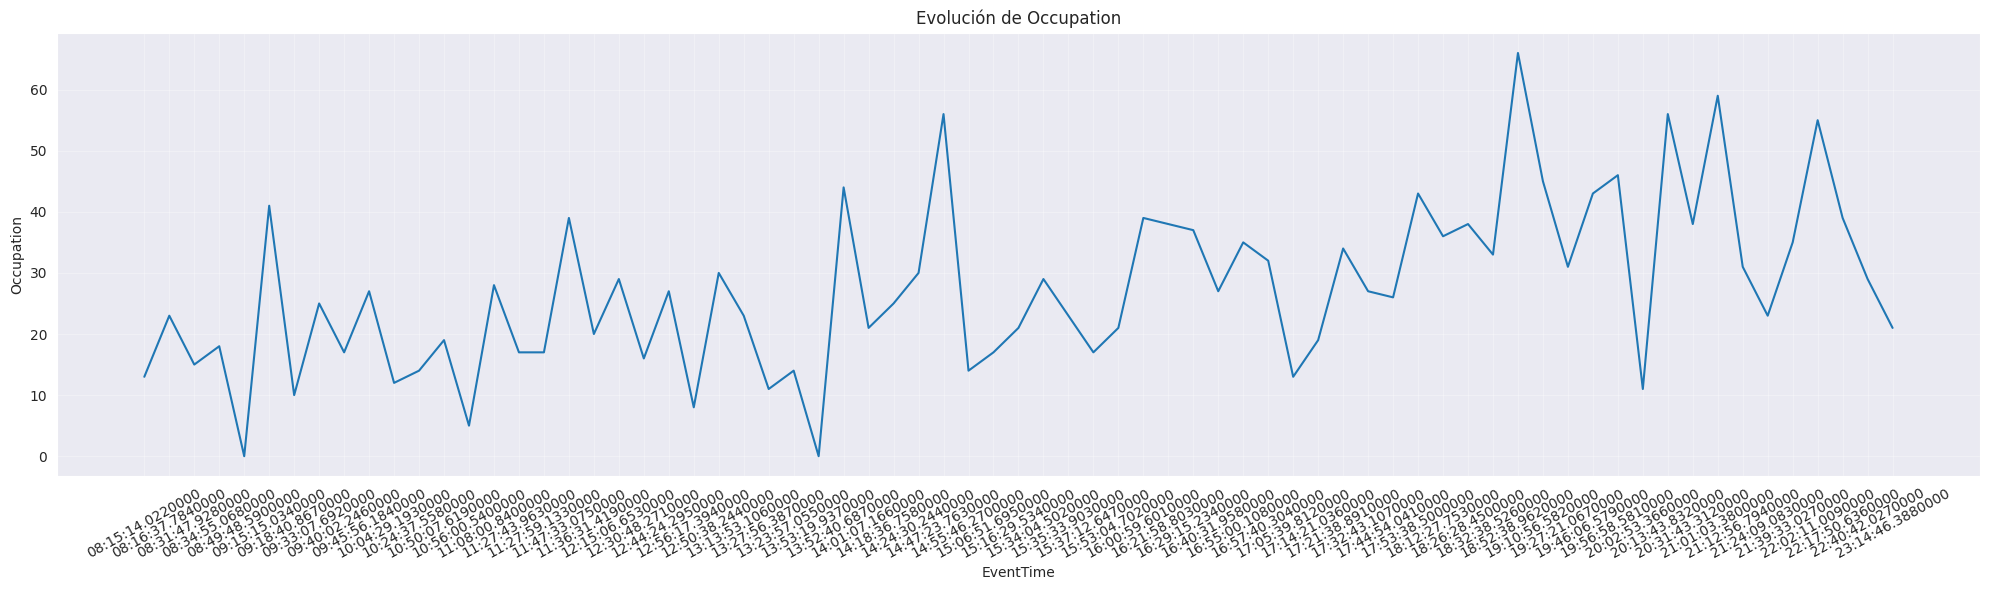

In [53]:
plt.figure(figsize=(20,6))
plt.plot(data_22_9["EventTime"][15:], data_22_9["Occupation"][15:])
plt.xlabel('EventTime')
plt.ylabel('Occupation')
plt.title('Evolución de Occupation')
plt.xticks(rotation=29)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

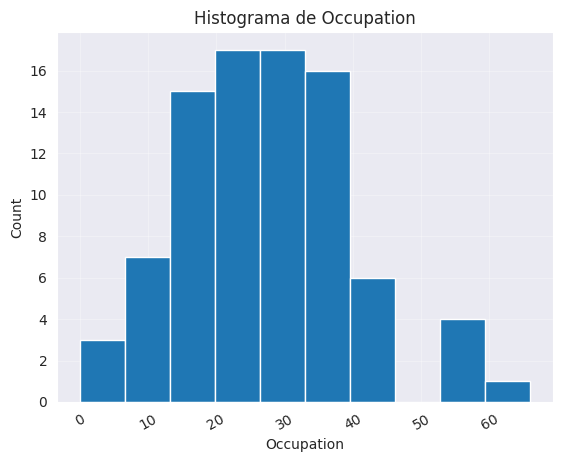

In [54]:
plt.hist(data_22_9["Occupation"])
plt.xlabel('Occupation')
plt.ylabel('Count')
plt.title('Histograma de Occupation')
plt.xticks(rotation=29)
plt.grid(True, alpha=0.3)
plt.show()